# Objectifs d'apprentissage – Semaine 11

À l'issue de cette semaine, l'étudiant sera capable de :

- **Comprendre** les contraintes et les spécificités du DSP embarqué (temps réel, ressources limitées, quantification).
- **Identifier** les principales fonctionnalités de la bibliothèque CMSIS‑DSP pour les microcontrôleurs ARM Cortex‑M.
- **Simuler** en Python des fonctions CMSIS‑DSP courantes (filtres FIR, FFT, fonctions mathématiques).
- **Mettre en œuvre** un filtre FIR en virgule fixe (format Q) et analyser l'impact de la quantification.
- **Calculer** une FFT sur des données en virgule fixe et interpréter les résultats.
- **Proposer** une architecture logicielle pour une application DSP embarquée.
- **Préparer** une proposition de projet final intégrant du DSP sur STM32.

# 1. Introduction au DSP embarqué

Le traitement numérique du signal en environnement embarqué (microcontrôleurs, DSP, FPGA) présente des **contraintes spécifiques** :

- **Ressources limitées** : mémoire (RAM/ROM), puissance de calcul, consommation énergétique.
- **Temps réel** : les traitements doivent être effectués dans un temps imparti (latence, périodes d'échantillonnage).
- **Arithmétique en virgule fixe** : les microcontrôleurs sans FPU (Floating Point Unit) utilisent des entiers (Q format) pour les calculs.
- **Optimisation** : utilisation d'instructions SIMD, de bibliothèques optimisées (CMSIS‑DSP), et de techniques de réduction de la complexité.

## 1.1 La bibliothèque CMSIS‑DSP

CMSIS‑DSP (Cortex Microcontroller Software Interface Standard - DSP) est une bibliothèque optimisée pour les processeurs ARM Cortex‑M. Elle fournit des fonctions pour :
- Filtres FIR et IIR (en virgule flottante et fixe).
- Transformées (FFT, DCT, etc.).
- Fonctions mathématiques (sin, cos, atan2, etc.).
- Statistiques (moyenne, variance, etc.).
- Matrices et vecteurs.

Les fonctions sont disponibles en versions `_f32` (flottant 32 bits) et `_q15`/`_q31` (virgule fixe Q15/Q31).

## 1.2 Format Q (virgule fixe)

Le format Qm.n est une représentation en virgule fixe où m bits sont consacrés à la partie entière (incluant le signe) et n bits à la partie fractionnaire. Par exemple :
- **Q15** : 1 bit de signe, 15 bits fractionnaires → valeurs entre -1 et 1, précision de 1/32768.
- **Q31** : 1 bit de signe, 31 bits fractionnaires → valeurs entre -1 et 1, précision plus fine.

En Python, on peut simuler le format Q en utilisant des entiers et des opérations de décalage.

---

# 2. Simulation de fonctions CMSIS‑DSP en Python

Nous allons simuler quelques fonctions clés de CMSIS‑DSP en Python pour comprendre leur fonctionnement sans matériel. Les implémentations Python ne seront pas optimisées, mais reproduiront les résultats numériques attendus.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq

print("Bibliothèques chargées.")

Bibliothèques chargées.


## 2.1 Conversion Q15

Simulons la conversion float ↔ Q15.

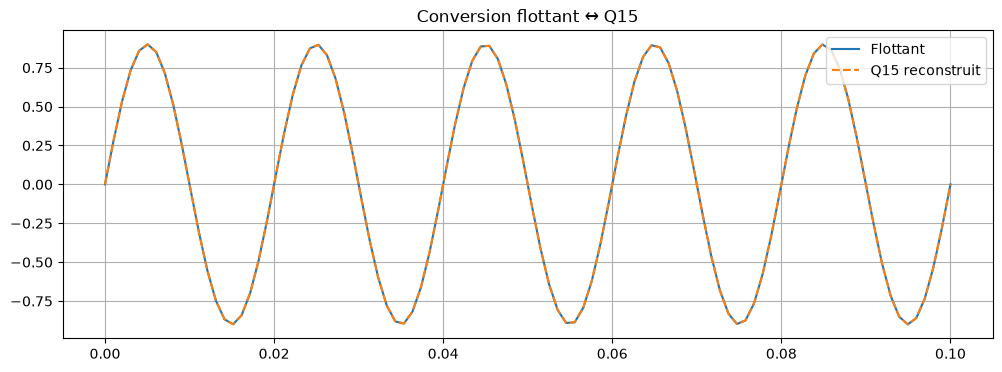

In [14]:
def float_to_q15(x):
    """Convertit un flottant (dans [-1, 1]) en entier Q15 (int16)."""
    x_sat = np.clip(x, -1.0, 1.0)
    return np.round(x_sat * 32767).astype(np.int16)

def q15_to_float(x_q):
    """Convertit un entier Q15 (int16) en flottant."""
    return x_q.astype(np.float32) / 32767.0

# Exemple
t = np.linspace(0, 0.1, 100)
signal_float = 0.9 * np.sin(2*np.pi*50*t)

signal_q15 = float_to_q15(signal_float)
signal_reconstruit = q15_to_float(signal_q15)

plt.figure(figsize=(12, 4))
plt.plot(t, signal_float, label='Flottant')
plt.plot(t, signal_reconstruit, '--', label='Q15 reconstruit')
plt.legend()
plt.grid()
plt.title('Conversion flottant ↔ Q15')
plt.show()

## 2.2 Filtre FIR en Q15 (simulation de arm_fir_q15)

Nous allons simuler un filtre FIR en utilisant des opérations Q15. La fonction `arm_fir_q15` utilise des accumulateurs en Q31 pour éviter les débordements.

C:\Users\nourk\AppData\Local\Temp\ipykernel_21484\3077985749.py:19: RuntimeWarning: overflow encountered in scalar add
  acc += np.int32(state[k]) * np.int32(b_q[k])


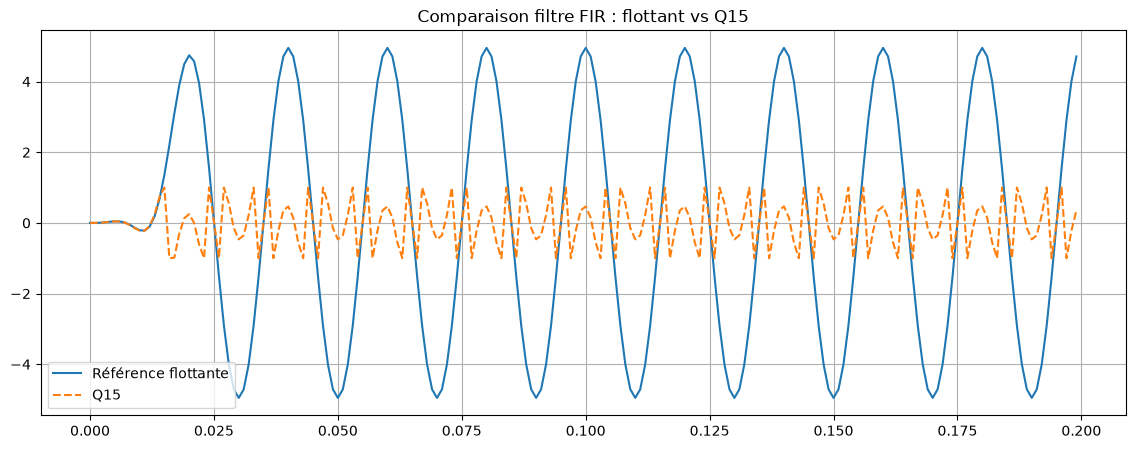

Erreur maximale : 4.574916


In [15]:
def fir_q15(x_q, b_q):
    """Simule un filtre FIR en Q15.
    x_q : entrée en Q15 (int16)
    b_q : coefficients en Q15 (int16)
    Retourne la sortie en Q15.
    """
    M = len(b_q)
    N = len(x_q)
    y_q = np.zeros(N, dtype=np.int16)
    # Buffer d'état (en Q15)
    state = np.zeros(M, dtype=np.int16)
    for n in range(N):
        # Mise à jour du buffer (décalage)
        state[1:] = state[:-1]
        state[0] = x_q[n]
        # Accumulateur en Q31 (32 bits) pour éviter les débordements
        acc = np.int32(0)
        for k in range(M):
            acc += np.int32(state[k]) * np.int32(b_q[k])
        # On décale de 15 pour repasser en Q15 (car produit de deux Q15 donne Q30, on ramène en Q15)
        # Attention : arrondi
        acc = (acc + (1 << 14)) >> 15
        # Saturation
        acc = np.clip(acc, -32768, 32767)
        y_q[n] = acc.astype(np.int16)
    return y_q

# Conception d'un filtre FIR passe-bas en flottant
fs = 1000
fc = 100
N_taps = 31
b_float = signal.firwin(N_taps, fc, fs=fs, window='hamming')

# Normalisation et conversion en Q15
b_float = b_float / np.max(np.abs(b_float))  # normalisation pour rester dans [-1, 1]
b_q15 = float_to_q15(b_float)

# Signal d'entrée en flottant et conversion Q15
t = np.linspace(0, 0.2, 200, endpoint=False)
x_float = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*200*t)
x_q15 = float_to_q15(x_float)

# Filtrage en Q15
y_q15 = fir_q15(x_q15, b_q15)
y_float_reconstruit = q15_to_float(y_q15)

# Filtrage en flottant pour référence
y_float_ref = signal.lfilter(b_float, 1, x_float)

# Comparaison
plt.figure(figsize=(14, 5))
plt.plot(t, y_float_ref, label='Référence flottante')
plt.plot(t, y_float_reconstruit, '--', label='Q15')
plt.legend()
plt.grid()
plt.title('Comparaison filtre FIR : flottant vs Q15')
plt.show()

err = np.max(np.abs(y_float_ref - y_float_reconstruit))
print(f"Erreur maximale : {err:.6f}")

## 2.3 FFT en Q15 (simulation de arm_rfft_q15)

La FFT en Q15 nécessite une mise à l'échelle pour éviter les débordements. Nous allons simuler une FFT sur des données Q15 et comparer avec la FFT flottante.

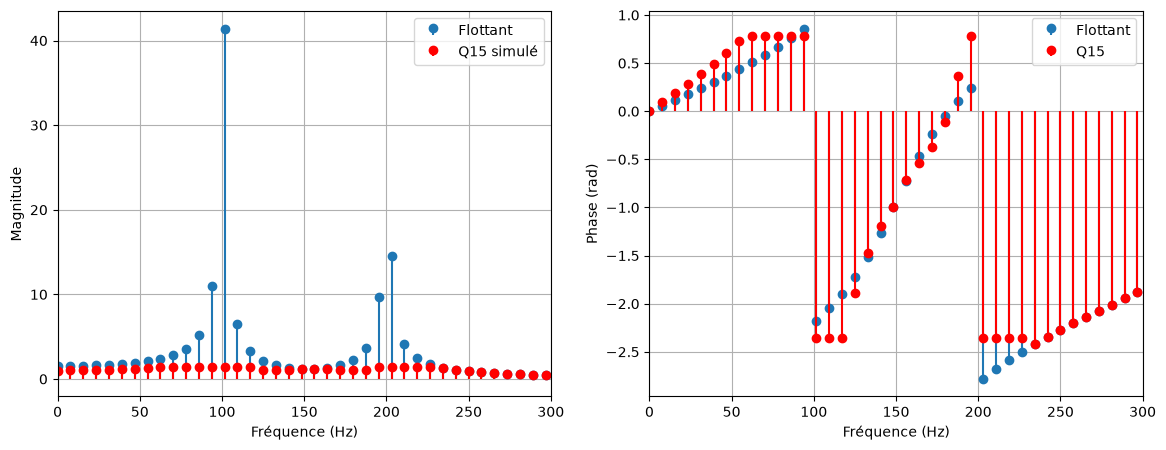

La version Q15 introduit une légère dégradation due à la quantification.


In [16]:
# Simulation d'une FFT en Q15
# Pour simplifier, on utilise la FFT flottante puis on quantifie les résultats en Q15
# Dans CMSIS-DSP, la FFT est implémentée en utilisant des rotations Q15 et des additions/soustractions avec saturation.

N_fft = 128
fs = 1000
t_fft = np.arange(N_fft) / fs
x_float = 0.7 * np.sin(2*np.pi*100*t_fft) + 0.3 * np.sin(2*np.pi*200*t_fft)

# FFT flottante
X_float = fft(x_float)[:N_fft//2]

# Conversion en Q15
x_q15 = float_to_q15(x_float)

# Simulation de la FFT Q15 : on effectue la FFT en flottant puis on quantifie les résultats
# Dans la réalité, la FFT Q15 utilise des étapes de mise à l'échelle.
X_q15_float = fft(q15_to_float(x_q15))[:N_fft//2]
# On quantifie les résultats en Q15 pour simuler la sortie de arm_rfft_q15
# La sortie de arm_rfft_q15 est généralement en Q15 pour la partie réelle et imaginaire.
X_q15_real = float_to_q15(np.real(X_q15_float))
X_q15_imag = float_to_q15(np.imag(X_q15_float))
X_q15 = q15_to_float(X_q15_real) + 1j * q15_to_float(X_q15_imag)

freqs = fftfreq(N_fft, 1/fs)[:N_fft//2]

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.stem(freqs, np.abs(X_float), basefmt=' ', label='Flottant')
plt.stem(freqs, np.abs(X_q15), linefmt='r-', markerfmt='ro', basefmt=' ', label='Q15 simulé')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Magnitude')
plt.xlim(0, 300)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.stem(freqs, np.angle(X_float), basefmt=' ', label='Flottant')
plt.stem(freqs, np.angle(X_q15), linefmt='r-', markerfmt='ro', basefmt=' ', label='Q15')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.show()

print("La version Q15 introduit une légère dégradation due à la quantification.")

## 2.4 Fonctions mathématiques (sin, cos, atan2) en Q15

CMSIS‑DSP fournit des tables de recherche pour les fonctions trigonométriques en Q15. Simulons un calcul de sinus en Q15 à l'aide d'une table.

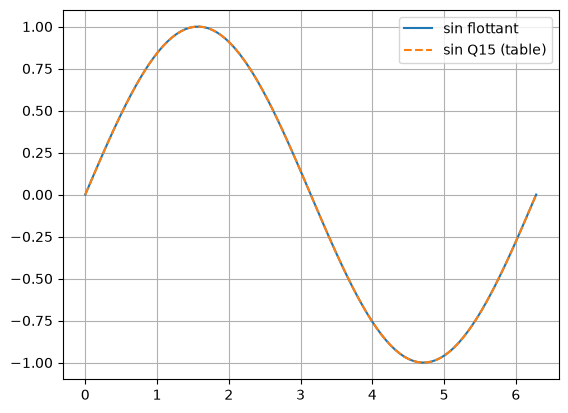

In [17]:

# Table de sinus Q15 pour 360 degrés (ou 2*pi radians)
# En pratique, la table est stockée dans la mémoire du microcontrôleur.
def sin_q15(angle_q15):
    """Simule arm_sin_q15 : angle en Q15 (0 correspond à 0 rad, 32767 correspond à 2*pi)."""
    # angle_q15 est un entier int16 entre 0 et 32767 représentant 0 à 2*pi
    # On utilise une interpolation linéaire sur une table de 256 points
    n_points = 256
    table = np.sin(2*np.pi * np.arange(n_points) / n_points)

    # Convertir angle_q15 en index 0..n_points-1
    angle_q15 = int(angle_q15)
    idx = (angle_q15 * n_points) // 32768
    idx = np.clip(idx, 0, n_points-1)

    # Interpolation linéaire
    frac = (angle_q15 * n_points) % 32768 / 32768.0
    val = (1-frac) * table[idx] + frac * table[(idx+1) % n_points]
    return float_to_q15(val)

# Test
angles = np.linspace(0, 2*np.pi, 100)
sin_float = np.sin(angles)
sin_q15_vals = np.array([sin_q15(float_to_q15(angle/(2*np.pi))) for angle in angles])
sin_reconst = q15_to_float(sin_q15_vals)

plt.plot(angles, sin_float, label='sin flottant')
plt.plot(angles, sin_reconst, '--', label='sin Q15 (table)')
plt.legend()
plt.grid()
plt.show()


# 3. Atelier : Mise en œuvre d'une application DSP embarquée

Nous allons simuler une application complète : un filtre anti-repliement (passe-bas) suivi d'une FFT pour analyser un signal, en utilisant des fonctions en virgule fixe. L'architecture est typique d'un système embarqué temps réel : acquisition (ADC), filtrage, FFT, puis communication ou affichage.

C:\Users\nourk\AppData\Local\Temp\ipykernel_21484\3077985749.py:19: RuntimeWarning: overflow encountered in scalar add
  acc += np.int32(state[k]) * np.int32(b_q[k])


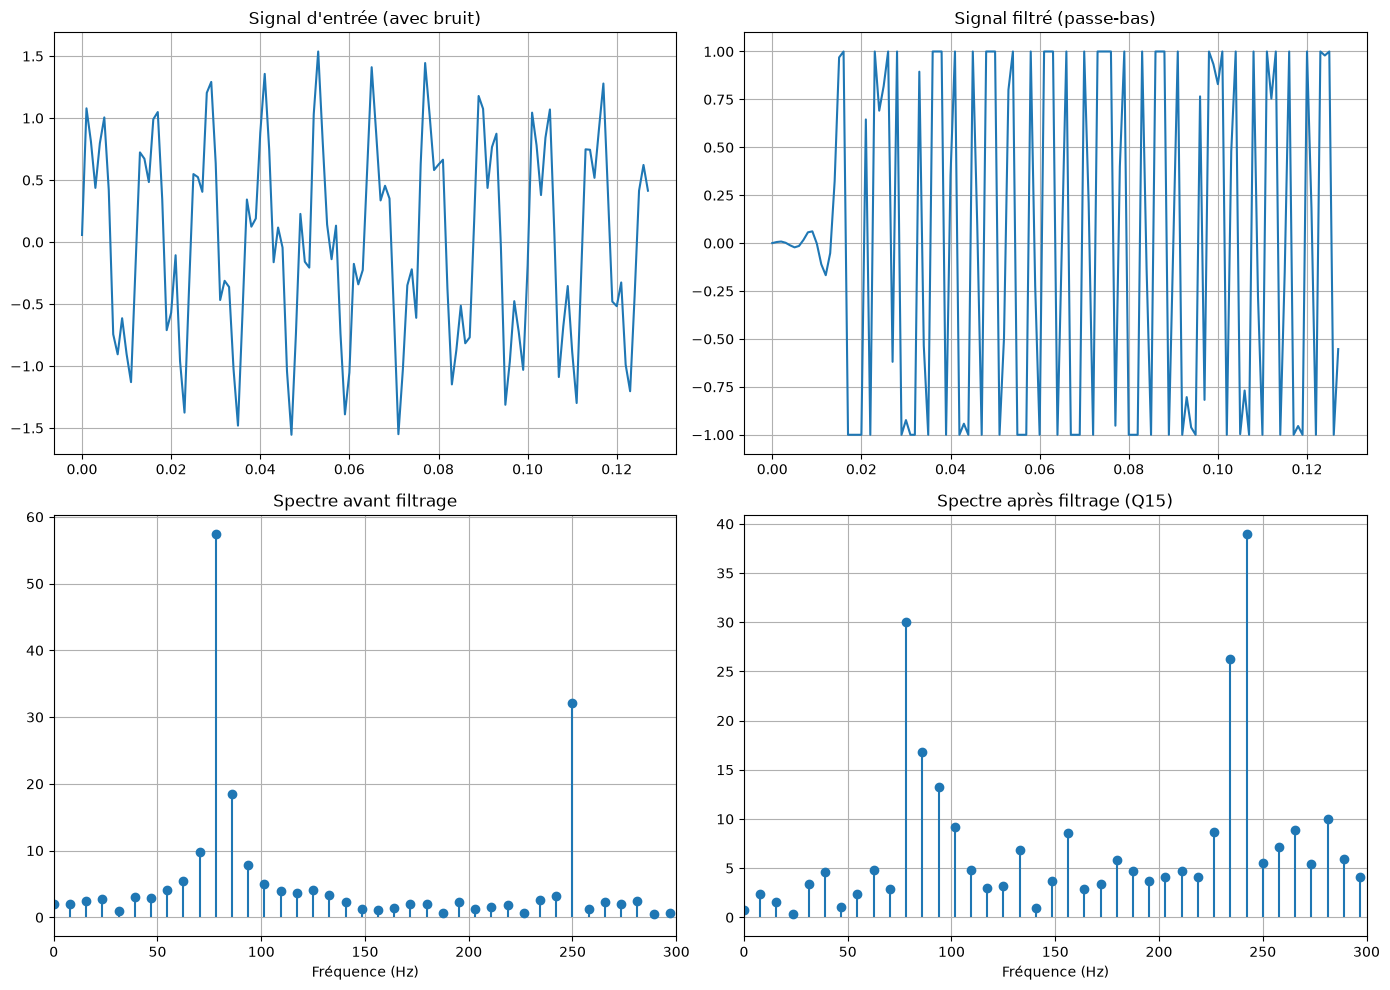

Taille du filtre : 31 coefficients en Q15
Nombre d'échantillons FFT : 128
En pratique, ces opérations peuvent être réalisées par CMSIS-DSP sur un Cortex-M4 en temps réel.


In [18]:
# Paramètres système
fs = 1000
N_samples = 128
t = np.arange(N_samples) / fs

# Signal d'entrée simulé (mélange de fréquences)
x_float = np.sin(2*np.pi*80*t) + 0.5*np.sin(2*np.pi*250*t) + 0.1*np.random.randn(N_samples)

# 1. Filtre anti-repliement (passe-bas en Q15)
# Conception du filtre en flottant
fc = 150
b_float = signal.firwin(31, fc, fs=fs, window='hamming')
b_float = b_float / np.max(np.abs(b_float))
b_q15 = float_to_q15(b_float)

# Conversion entrée en Q15
x_q15 = float_to_q15(x_float)

# Filtrage
y_q15 = fir_q15(x_q15, b_q15)
y_float = q15_to_float(y_q15)

# 2. FFT en Q15 sur le signal filtré
# (simulée comme précédemment)
X_q15_real = float_to_q15(np.real(fft(y_float)[:N_samples//2]))
X_q15_imag = float_to_q15(np.imag(fft(y_float)[:N_samples//2]))
X_q15 = q15_to_float(X_q15_real) + 1j*q15_to_float(X_q15_imag)

freqs = fftfreq(N_samples, 1/fs)[:N_samples//2]

# Visualisation
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1)
plt.plot(t, x_float)
plt.title('Signal d\'entrée (avec bruit)')
plt.grid()

plt.subplot(2, 2, 2)
plt.plot(t, y_float)
plt.title('Signal filtré (passe-bas)')
plt.grid()

plt.subplot(2, 2, 3)
plt.stem(freqs, np.abs(fft(x_float)[:N_samples//2]), basefmt=' ')
plt.title('Spectre avant filtrage')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 300)
plt.grid()

plt.subplot(2, 2, 4)
plt.stem(freqs, np.abs(fft(y_float)[:N_samples//2]), basefmt=' ')
plt.title('Spectre après filtrage (Q15)')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 300)
plt.grid()

plt.tight_layout()
plt.show()

# Bilan des ressources simulées
print(f"Taille du filtre : {len(b_q15)} coefficients en Q15")
print(f"Nombre d'échantillons FFT : {N_samples}")
print("En pratique, ces opérations peuvent être réalisées par CMSIS-DSP sur un Cortex-M4 en temps réel.")

# 4. Exercices – Semaine 11

## Exercice 1 – Filtre RII en Q15

1. Concevoir un filtre RII Butterworth passe-bas d'ordre 4 avec fc=100 Hz, fs=1000 Hz.
2. Convertir les coefficients en Q15 (normalisation puis quantification).
3. Implémenter une fonction `iir_q15` simulant un filtre RII en Q15 (structure directe II) en utilisant un accumulateur Q31.
4. Tester sur un signal bruité et comparer avec la version flottante.
5. Discuter de la stabilité : que se passe-t-il si l'ordre est trop élevé en Q15 ?

**Code** :

Coefficients a : [ 1.         -2.36951301  2.31398841 -1.05466541  0.18737949]
Coefficients b : [0.00482434 0.01929737 0.02894606 0.01929737 0.00482434]
Format des coefficients : Q3.13
b_q : [ 40 158 237 158  40]
a_q : [  8192 -19411  18956  -8640   1535]


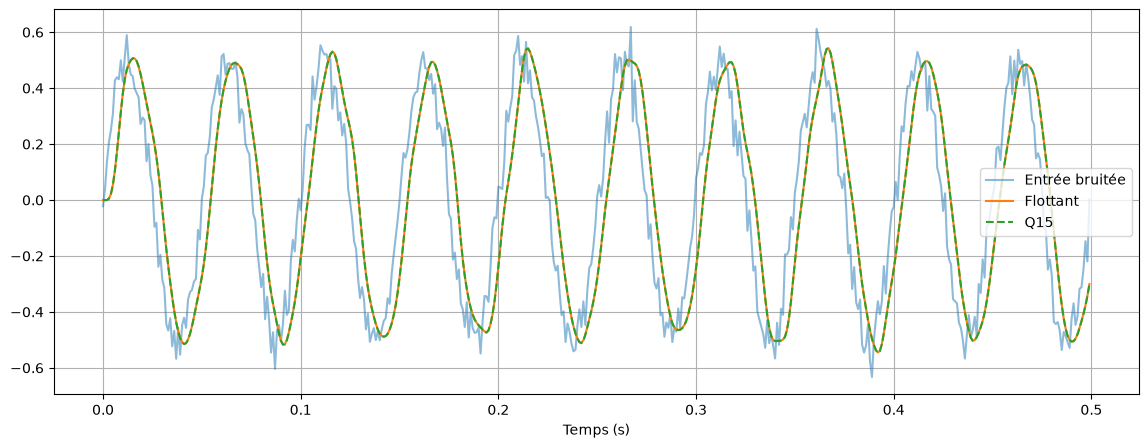

Erreur max (Q15 vs flottant) : 0.0007812116185212936
Erreur max (Q15 vs flottant à coefficients quantifiés) : 2.5092811882176935e-05
RSB de quantification (dB) : 56.585468023589115
Ordre  2 : format Q2.14, |p| max = 0.6425, stable = True
Ordre  4 : format Q3.13, |p| max = 0.7953, stable = True
Ordre  6 : format Q4.12, |p| max = 0.8586, stable = True
Ordre  8 : format Q5.11, |p| max = 0.8923, stable = True
Ordre 10 : format Q7.9, |p| max = 1.0476, stable = False
Ordre 12 : format Q8.8, |p| max = 1.2227, stable = False


In [19]:
# À compléter
def iir_q15(x_q, b_q, a_q):
    # a_q[0] doit être 1 en Q15 (c'est-à-dire 32767)
    # Implémenter la structure directe II en Q15
    shift = int(np.round(np.log2(int(a_q[0]) + 1)))
    half = 1 << (shift - 1)
    s = [0] * (len(a_q) - 1)
    y_q = np.zeros(len(x_q), dtype=np.int16)
    for n in range(len(x_q)):
        acc = int(x_q[n]) << shift
        for k in range(1, len(a_q)):
            acc -= int(a_q[k]) * s[k-1]
        acc = max(-(1 << 31), min((1 << 31) - 1, acc))
        w0 = (acc + half) >> shift
        acc_y = int(b_q[0]) * w0
        for k in range(1, len(b_q)):
            acc_y += int(b_q[k]) * s[k-1]
        acc_y = max(-(1 << 31), min((1 << 31) - 1, acc_y))
        y_q[n] = max(-32768, min(32767, (acc_y + half) >> shift))
        s = [w0] + s[:-1]
    return y_q

# Test

fs = 1000
fc = 100
b, a = signal.butter(4, fc, fs=fs, btype='low')
print("Coefficients a :", a)
print("Coefficients b :", b)

shift = 15 - int(np.ceil(np.log2(np.max(np.abs(np.concatenate((b, a)))))))
b_q = np.clip(np.round(b * 2**shift), -32768, 32767).astype(np.int16)
a_q = np.clip(np.round(a * 2**shift), -32768, 32767).astype(np.int16)
print(f"Format des coefficients : Q{16 - shift}.{shift}")
print("b_q :", b_q)
print("a_q :", a_q)

t = np.arange(500) / fs
x_float = 0.5*np.sin(2*np.pi*20*t) + 0.05*np.random.randn(len(t))
x_q = float_to_q15(x_float)

y_q = iir_q15(x_q, b_q, a_q)
y_fix = q15_to_float(y_q)
y_ref = signal.lfilter(b, a, q15_to_float(x_q))
y_ref_q = signal.lfilter(b_q / 2**shift, a_q / 2**shift, q15_to_float(x_q))

plt.figure(figsize=(14, 5))
plt.plot(t, x_float, alpha=0.5, label='Entrée bruitée')
plt.plot(t, y_ref, label='Flottant')
plt.plot(t, y_fix, '--', label='Q15')
plt.xlabel('Temps (s)')
plt.legend()
plt.grid()
plt.show()

print("Erreur max (Q15 vs flottant) :", np.max(np.abs(y_fix - y_ref)))
print("Erreur max (Q15 vs flottant à coefficients quantifiés) :", np.max(np.abs(y_fix - y_ref_q)))
print("RSB de quantification (dB) :", 10*np.log10(np.sum(y_ref**2) / np.sum((y_fix - y_ref)**2)))

for order in (2, 4, 6, 8, 10, 12):
    bo, ao = signal.butter(order, fc, fs=fs, btype='low')
    sh = 15 - int(np.ceil(np.log2(np.max(np.abs(np.concatenate((bo, ao)))))))
    ao_q = np.round(ao * 2**sh) / 2**sh
    p_max = np.max(np.abs(np.roots(ao_q)))
    print(f"Ordre {order:2d} : format Q{16 - sh}.{sh}, |p| max = {p_max:.4f}, stable = {p_max < 1}")

reponse theorique

**Question 1**

Le filtre Butterworth passe-bas d'ordre 4 ($f_c = 100$ Hz, $f_s = 1000$ Hz) a pour coefficients :
- $b = [0.0048,\ 0.0193,\ 0.0289,\ 0.0193,\ 0.0048]$
- $a = [1,\ -2.3695,\ 2.3140,\ -1.0547,\ 0.1874]$

Ses pôles sont à l'intérieur du cercle unité (module maximal ≈ 0.795) : le filtre est stable en précision double.

**Question 2**

Le format Q15 représente des valeurs dans $[-1, 1[$, or $|a_1| = 2.37 > 1$ : on ne peut pas coder ces coefficients en Q15. On les **normalise** par une puissance de 2 commune à $b$ et $a$ : le plus grand coefficient vaut 2.37 (< 4), donc on multiplie par $2^{13}$, ce qui donne le format **Q3.13** (3 bits entiers, signe compris, et 13 bits fractionnaires, plage $[-4, 4[$). On quantifie ensuite par arrondi :
- $b_q = [40,\ 158,\ 237,\ 158,\ 40]$
- $a_q = [8192,\ -19411,\ 18956,\ -8640,\ 1535]$

Dans ce format, $a_q[0] = 8192 = 2^{13}$ représente 1.0 (et non 32767, qui ne serait valable que si tous les coefficients étaient inférieurs à 1). La fonction retrouve le décalage à partir de $a_q[0]$.

**Question 3**

La fonction `iir_q15` implémente la structure directe II :

$$ w[n] = x[n] - \sum_{k=1}^{4} a_k\, w[n-k], \qquad y[n] = \sum_{k=0}^{4} b_k\, w[n-k] $$

- Les produits (Q15 × Q13) sont accumulés dans un accumulateur 32 bits en format Q28, avec saturation à $\pm 2^{31}$.
- Le résultat est ramené en Q15 par un décalage de 13 bits **avec arrondi**.
- La sortie $y[n]$ est saturée sur 16 bits.
- Les états $w[n-k]$ sont conservés sur 32 bits (en Q15) : le nœud interne de la structure directe II a un gain $1/A(z)$ qui peut atteindre ≈ 13 ($1/\sum b_k$), il dépasserait la plage d'un `int16`.

**Question 4**

Test sur un signal bruité (sinusoïde de 20 Hz d'amplitude 0.5 plus un bruit de 0.05) : la sortie Q15 suit la sortie flottante.
- L'erreur maximale est de l'ordre de $10^{-3}$ (≈ $8 \times 10^{-4}$), et le rapport signal sur bruit de quantification vaut environ 56 dB.
- Par rapport à un filtre flottant utilisant les coefficients quantifiés, l'erreur n'est plus que de ≈ $2 \times 10^{-5}$ : l'erreur vient donc surtout de la **quantification des coefficients** (qui déplace les pôles et les zéros), et très peu des arrondis du calcul.

**Question 5**

Quand l'ordre augmente, les coefficients de $a$ deviennent plus grands (ils suivent à peu près des coefficients binomiaux). Il faut donc plus de bits pour la partie entière, donc moins de bits pour la partie fractionnaire, et la précision des coefficients diminue. Or les pôles d'un filtre d'ordre élevé sont proches du cercle unité et très sensibles aux erreurs sur les coefficients. Résultats ($f_c = 100$ Hz, $f_s = 1000$ Hz, coefficients arrondis dans le meilleur format Q possible) :

| Ordre | Format | $|p|_{max}$ | Stable |
|---|---|---|---|
| 2 | Q2.14 | 0.64 | oui |
| 4 | Q3.13 | 0.80 | oui |
| 6 | Q4.12 | 0.86 | oui |
| 8 | Q5.11 | 0.89 | oui |
| 10 | Q7.9 | 1.05 | **non** |
| 12 | Q8.8 | 1.22 | **non** |

À partir de l'ordre 10, un pôle sort du cercle unité : le filtre devient **instable**. S'y ajoutent des risques de débordement du nœud interne et de cycles limites. La solution est de décomposer le filtre en **sections d'ordre 2 en cascade (biquads)**, qui ont des coefficients bornés (|coef| < 2) et sont beaucoup moins sensibles à la quantification.

## Exercice 2 – FFT en Q15 et fenêtrage

1. Générer un signal composé de deux sinusoïdes de fréquences 120 Hz et 130 Hz, fs=1000 Hz, N=64.
2. Appliquer une fenêtre de Hamming en Q15 (convertir la fenêtre en Q15).
3. Calculer la FFT en Q15 (simulée) et tracer le spectre.
4. Comparer la résolution spectrale avec et sans fenêtre.

**Code** :

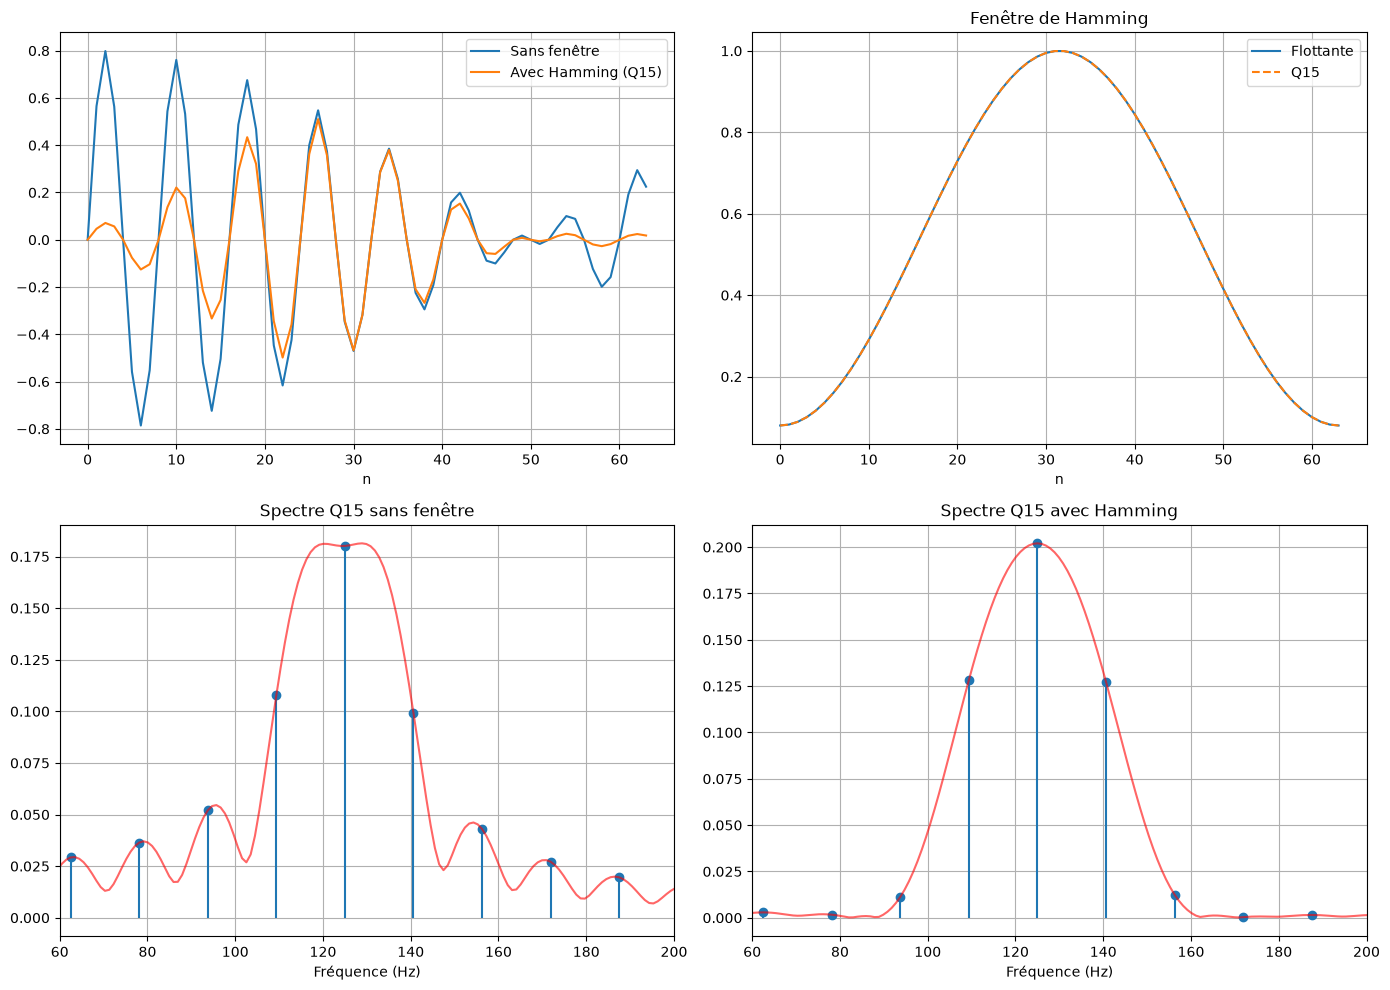

Résolution spectrale fs/N = 15.62 Hz, écart entre les sinusoïdes = 10 Hz
Sans fenêtre : pics à [120.1 128.9] Hz
Hamming : pics à [125.] Hz


In [21]:
# À compléter

fs = 1000
N = 64
n = np.arange(N)
x_float = 0.4*np.sin(2*np.pi*120*n/fs) + 0.4*np.sin(2*np.pi*130*n/fs)
x_q15 = float_to_q15(x_float)

fenetre = np.hamming(N)
w_q15 = float_to_q15(fenetre)
xw_q15 = ((x_q15.astype(np.int32) * w_q15.astype(np.int32) + (1 << 14)) >> 15).astype(np.int16)

def fft_q15_sim(x_q):
    X = fft(q15_to_float(x_q)) / len(x_q)
    return q15_to_float(float_to_q15(np.real(X))) + 1j*q15_to_float(float_to_q15(np.imag(X)))

X_rect = fft_q15_sim(x_q15)
X_hamm = fft_q15_sim(xw_q15)
freqs = fftfreq(N, 1/fs)[:N//2]

N_pad = 1024
f_pad = fftfreq(N_pad, 1/fs)[:N_pad//2]
S_rect = np.abs(fft(q15_to_float(x_q15), N_pad))[:N_pad//2] / N
S_hamm = np.abs(fft(q15_to_float(xw_q15), N_pad))[:N_pad//2] / np.sum(fenetre)

plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1)
plt.plot(n, x_float, label='Sans fenêtre')
plt.plot(n, q15_to_float(xw_q15), label='Avec Hamming (Q15)')
plt.xlabel('n')
plt.legend()
plt.grid()

plt.subplot(2, 2, 2)
plt.plot(n, fenetre, label='Flottante')
plt.plot(n, q15_to_float(w_q15), '--', label='Q15')
plt.title('Fenêtre de Hamming')
plt.xlabel('n')
plt.legend()
plt.grid()

plt.subplot(2, 2, 3)
plt.stem(freqs, np.abs(X_rect[:N//2]), basefmt=' ')
plt.plot(f_pad, S_rect, 'r', alpha=0.6)
plt.title('Spectre Q15 sans fenêtre')
plt.xlabel('Fréquence (Hz)')
plt.xlim(60, 200)
plt.grid()

plt.subplot(2, 2, 4)
plt.stem(freqs, np.abs(X_hamm[:N//2]) * N / np.sum(fenetre), basefmt=' ')
plt.plot(f_pad, S_hamm, 'r', alpha=0.6)
plt.title('Spectre Q15 avec Hamming')
plt.xlabel('Fréquence (Hz)')
plt.xlim(60, 200)
plt.grid()
plt.tight_layout()
plt.show()

print(f"Résolution spectrale fs/N = {fs/N:.2f} Hz, écart entre les sinusoïdes = 10 Hz")
for nom, S in (('Sans fenêtre', S_rect), ('Hamming', S_hamm)):
    pics, _ = signal.find_peaks(S, height=0.5*S.max())
    print(f"{nom} : pics à", np.round(f_pad[pics], 1), "Hz")

reponse theorique

**Question 1**

Le signal est la somme de deux sinusoïdes de 120 Hz et 130 Hz (amplitude 0.4 chacune, pour rester dans $[-1, 1]$) avec $f_s = 1000$ Hz et $N = 64$. La résolution spectrale vaut $f_s/N = 15.6$ Hz, alors que les deux fréquences sont séparées de seulement 10 Hz.

**Question 2**

La fenêtre de Hamming est calculée en flottant puis convertie en Q15 (`float_to_q15`). Le fenêtrage se fait en entier : produit Q15 × Q15 sur 32 bits (format Q30), arrondi, puis décalage de 15 bits pour revenir en Q15.

**Question 3**

La FFT Q15 est simulée comme dans le cours : FFT flottante des données Q15, puis quantification de la partie réelle et de la partie imaginaire en Q15. Pour éviter la saturation (les valeurs de la FFT peuvent atteindre $N \times A/2$, bien au-delà de 1), la sortie est **divisée par $N$**, ce qui correspond à la division par 2 à chaque étage de la FFT Q15 de CMSIS-DSP. Chaque sinusoïde d'amplitude 0.4 apparaît alors avec une magnitude proche de $A/2 = 0.2$ (valeur maximale observée ≈ 0.18, à cause de la fuite spectrale entre les deux raies).

**Question 4**

- **Sans fenêtre** (rectangulaire) : deux pics distincts apparaissent, à ≈ 120 Hz et ≈ 129 Hz. Les deux raies sont séparables mais de justesse, car 10 Hz est inférieur à la résolution nominale de 15.6 Hz. Le spectre garde des lobes secondaires importants (≈ -13 dB).
- **Avec Hamming** : un seul lobe large est visible, centré vers 125 Hz : les deux sinusoïdes ne sont plus séparables. Le lobe principal est plus large (environ $4 f_s/N \approx 62$ Hz), mais les lobes secondaires sont beaucoup plus faibles (≈ -43 dB).

La fenêtre de Hamming dégrade donc la résolution et améliore la dynamique. Pour séparer deux fréquences proches avec Hamming, il faudrait augmenter $N$ (ici $N \gtrsim 400$) ; le zero-padding ne change pas la résolution, il lisse seulement la courbe.

## Exercice 3 – Estimation de la consommation mémoire

Pour une application DSP embarquée, on doit estimer la mémoire nécessaire.

1. Un filtre FIR à 64 coefficients en Q15 (int16) est utilisé. Calculer la mémoire pour les coefficients, l'état (buffer circulaire), et le code si nécessaire.
2. Une FFT de 256 points en Q15 nécessite des tables de twiddle factors (rotations). Estimer la mémoire pour ces tables.
3. Proposer une optimisation pour réduire la mémoire (par exemple, utiliser des coefficients symétriques pour le FIR).

**Réponse** :
- Coefficients : 64 * 2 octets = 128 octets.
- Buffer d'état : 64 * 2 = 128 octets.
- Tables FFT (twiddle) : pour N=256, environ N/2 * 2 = 256 octets en Q15.
- Total : environ 512 octets, plus le code. On peut réduire en utilisant la symétrie pour le FIR (coefficients symétriques) ce qui permet de stocker la moitié des coefficients et d'utiliser une structure optimisée.

reponse theorique 
**Question 1**

Pour le filtre FIR de 64 coefficients en Q15 (`int16`, 2 octets) :
- **Coefficients** : $64 \times 2 = 128$ octets (en mémoire Flash, car constants) ;
- **État (buffer circulaire)** : 64 derniers échantillons, soit $64 \times 2 = 128$ octets (en RAM). Avec un traitement par blocs de $B$ échantillons, `arm_fir_q15` demande $(64 + B - 1) \times 2$ octets ;
- **Code** : quelques centaines d'octets en Flash (ordre de grandeur, qui dépend du compilateur et de la bibliothèque).

**Question 2**

Une FFT complexe de 256 points utilise les facteurs de rotation $W_{256}^k$ pour $k = 0, \dots, 127$ (grâce à la structure radix-2, $N/2 = 128$ valeurs différentes). Chaque facteur est complexe (cosinus et sinus), codé sur $2 \times 2$ octets :
- stockage minimal : $128 \times 4 = 512$ octets ;
- avec une table complète de $N$ facteurs complexes (comme le fait CMSIS-DSP, soit environ $2N$ valeurs Q15) : $256 \times 4 \approx 1024$ octets (1 Ko).

À cela s'ajoute le buffer de données de la FFT : 256 échantillons complexes en Q15, soit $256 \times 4 = 1024$ octets (ou 512 octets pour une entrée réelle).

Estimation de la mémoire totale (sans le code) : ≈ 128 (coefficients) + 128 (état) + 512 à 1024 (twiddle) + 512 à 1024 (buffer FFT), soit environ **1,3 à 2,3 Ko**. Cette valeur reste très petite devant les 64 à 128 Ko de RAM d'un STM32 courant.

**Question 3**

Optimisations possibles :
- **FIR symétrique** : on ne stocke que la moitié des coefficients (32 au lieu de 64, soit 64 octets au lieu de 128) et on utilise la structure symétrique (32 multiplications au lieu de 64 par échantillon) ;
- **Table de twiddle réduite** : on exploite la symétrie du sinus/cosinus pour ne stocker qu'un quart d'onde ($N/4 = 64$ valeurs, soit 128 octets), au prix d'un petit calcul d'indice ;
- **FFT réelle** : une FFT réelle de 256 points se calcule avec une FFT complexe de 128 points, ce qui divise par deux les tables et le buffer ;
- **FFT en place** (sans buffer de sortie séparé) et coefficients en `const` (Flash) pour libérer de la RAM.

## Exercice 4 – Proposition de projet final

Rédiger une proposition de projet intégrant du DSP sur STM32 avec CMSIS‑DSP. La proposition doit inclure :
- Objectif du projet (ex : analyse de signaux ECG, traitement audio, contrôle moteur).
- Spécifications techniques (fréquence d'échantillonnage, nombre de canaux, type de traitement).
- Choix des algorithmes (filtres, FFT, etc.) et justification.
- Estimation des ressources (temps de calcul, mémoire).
- Plan de développement.

**Rédiger la proposition dans une cellule Markdown.**

**Proposition de projet : moniteur ECG temps réel sur STM32**

**1. Objectif du projet**

Concevoir un moniteur d'électrocardiogramme (ECG) à une voie, sur un STM32 (Cortex-M4F) avec CMSIS-DSP. Le système acquiert le signal ECG, supprime les perturbations (dérive de la ligne de base, secteur à 50 Hz, bruit musculaire), détecte les complexes QRS et calcule la fréquence cardiaque en temps réel.

**2. Spécifications techniques**

- Carte : STM32F411 (Cortex-M4F, 100 MHz, 128 Ko de RAM, 512 Ko de Flash).
- Fréquence d'échantillonnage : $f_s = 500$ Hz (période de 2 ms), 1 canal (extensible à 2), ADC 12 bits déclenché par un timer et transfert par DMA (double buffer de 32 échantillons).
- Bande utile de l'ECG : 0.5 à 40 Hz.
- Sorties : fréquence cardiaque (bpm) et indicateur de qualité du signal, envoyés par UART ; affichage de la courbe sur PC.

**3. Choix des algorithmes et justification**

- **Passe-haut 0.5 Hz** (RII Butterworth d'ordre 2, un biquad) : supprime la dérive de la ligne de base avec très peu de calculs.
- **Coupe-bande 50 Hz** (RII, un biquad, $Q \approx 30$) : supprime le secteur sans toucher au reste du spectre.
- **Passe-bas 40 Hz** (RIF à phase linéaire, 31 coefficients, Hamming) : conserve la forme du QRS, car la phase linéaire évite la distorsion de phase.
- **Détection QRS** (algorithme de Pan-Tompkins simplifié : dérivée, mise au carré, moyenne glissante de 150 ms, seuil adaptatif) : algorithme simple, peu coûteux et robuste.
- **FFT de 256 points** (`arm_rfft_q15`), calculée périodiquement : estimation de la puissance résiduelle à 50 Hz pour évaluer la qualité du signal.
- Calcul en virgule flottante 32 bits (`_f32`, la FPU du M4F le permet) pour les filtres RII ; le RIF et la FFT peuvent passer en Q15 pour réduire le temps de calcul et la mémoire.

**4. Estimation des ressources (ordres de grandeur, à valider par mesure)**

- **Temps de calcul** : le budget est de 2 ms par échantillon, soit 200 000 cycles à 100 MHz. Le traitement par échantillon (deux biquads, RIF 31 coefficients, détection QRS) prend de l'ordre de quelques centaines de cycles. La FFT de 256 points prend de l'ordre de 10 000 cycles et n'est calculée que toutes les 128 échantillons. La charge totale du processeur reste inférieure à 5 %.
- **Mémoire** : coefficients et états des filtres < 1 Ko ; buffer FFT et tables de twiddle ≈ 2 Ko ; historique de 10 s d'ECG en Q15 ($5000 \times 2$ octets) = 10 Ko. Total en RAM < 20 Ko, soit moins de 20 % de la RAM disponible.

**5. Plan de développement**

1. **Simulation en Python** : conception des filtres (SciPy), test sur la base MIT-BIH Arrhythmia et réglage de la détection QRS.
2. **Mise en œuvre sur STM32** : configuration de l'ADC, du timer et du DMA (STM32CubeIDE), puis intégration de CMSIS-DSP.
3. **Portage des algorithmes en C** : filtres, détection QRS et FFT ; comparaison des sorties avec la simulation Python (erreur maximale).
4. **Tests et validation** : mesure du temps de calcul réel (compteur de cycles DWT), évaluation de la sensibilité et de la précision de la détection QRS (objectif > 99 % sur des enregistrements propres).
5. **Rapport et démonstration** : documentation, résultats et démonstration en temps réel.

## Exercice 5 – Simulation d'une application temps réel

On souhaite simuler un traitement temps réel sur un microcontrôleur. On considère un buffer circulaire de 128 échantillons, un filtre FIR de 31 coefficients, et une FFT de 128 points.

1. Écrire un code Python qui simule le traitement en continu : chaque itération, on ajoute un nouvel échantillon, on met à jour le buffer, on applique le filtre et on calcule la FFT sur les 128 derniers échantillons.
2. Mesurer le temps d'exécution de chaque étape (utiliser `time.perf_counter`).
3. Estimer si un Cortex-M4 à 100 MHz peut respecter une période d'échantillonnage de 1 ms.
4. Proposer des optimisations (ex : utiliser la FFT uniquement tous les N échantillons).

**Code** :

Mise à jour du buffer : 24.9 µs en moyenne
Filtre FIR (31 coef.) : 15.0 µs en moyenne
FFT (128 points) : 88.5 µs en moyenne


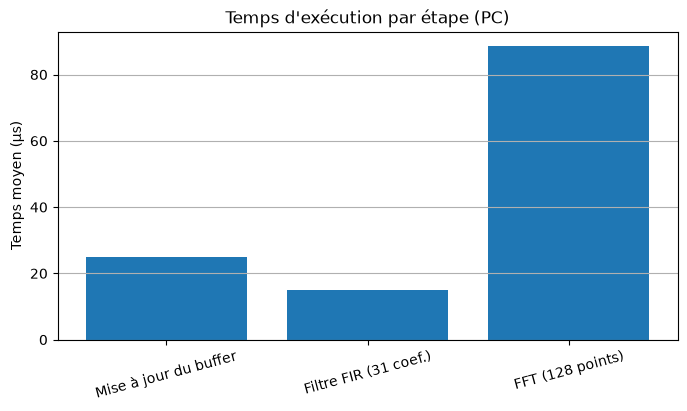

Budget par échantillon : 100000 cycles
FIR : 124 cycles, FFT : 5376 cycles, mise à jour : 20 cycles
Total (FFT à chaque échantillon) : 5520 cycles = 5.5 % du budget
FFT tous les 64 échantillons : 228 cycles = 0.23 % du budget


In [22]:
# À compléter
# Exemple de structure
import time

buffer_size = 128
buffer = np.zeros(buffer_size)

b_fir = signal.firwin(31, 100, fs=1000, window='hamming')
t_maj = []
t_filtre = []
t_fft = []
sortie = []

# Simulation de l'acquisition
for n in range(200):
    # Nouvel échantillon (simulé)
    new_sample = np.random.randn()
    t0 = time.perf_counter()
    # Mise à jour du buffer circulaire
    buffer = np.roll(buffer, -1)
    buffer[-1] = new_sample
    t1 = time.perf_counter()
    t_maj.append(t1 - t0)
    # Filtrage (si n > taille filtre)
    if n >= len(b_fir):
        t1 = time.perf_counter()
        y_n = np.dot(b_fir, buffer[-len(b_fir):][::-1])
        t2 = time.perf_counter()
        sortie.append(y_n)
        t_filtre.append(t2 - t1)
    # FFT (périodique)
    if n >= buffer_size - 1:
        t2 = time.perf_counter()
        spectre = np.abs(np.fft.fft(buffer))
        t3 = time.perf_counter()
        t_fft.append(t3 - t2)

moy = {'Mise à jour du buffer': np.mean(t_maj), 'Filtre FIR (31 coef.)': np.mean(t_filtre), 'FFT (128 points)': np.mean(t_fft)}
for nom, valeur in moy.items():
    print(f"{nom} : {valeur*1e6:.1f} µs en moyenne")

plt.figure(figsize=(8, 4))
plt.bar(list(moy.keys()), [v*1e6 for v in moy.values()])
plt.ylabel('Temps moyen (µs)')
plt.title("Temps d'exécution par étape (PC)")
plt.xticks(rotation=15)
plt.grid(axis='y')
plt.show()

f_cpu = 100e6
T_ech = 1e-3
cycles_budget = f_cpu * T_ech
cycles_fir = 4 * len(b_fir)
cycles_fft = 12 * (buffer_size // 2) * int(np.log2(buffer_size))
cycles_maj = 20
cycles_total = cycles_fir + cycles_fft + cycles_maj

print(f"Budget par échantillon : {cycles_budget:.0f} cycles")
print(f"FIR : {cycles_fir} cycles, FFT : {cycles_fft} cycles, mise à jour : {cycles_maj} cycles")
print(f"Total (FFT à chaque échantillon) : {cycles_total} cycles = {cycles_total/cycles_budget*100:.1f} % du budget")

N_fft_periode = 64
cycles_opt = cycles_fir + cycles_maj + cycles_fft / N_fft_periode
print(f"FFT tous les {N_fft_periode} échantillons : {cycles_opt:.0f} cycles = {cycles_opt/cycles_budget*100:.2f} % du budget")

reponse theorique

**Question 1**

On simule le traitement en continu : à chaque itération, un nouvel échantillon est ajouté au buffer de 128 échantillons (`np.roll` puis écriture du dernier élément), on applique le filtre FIR à 31 coefficients sur les 31 derniers échantillons (`np.dot`), puis on calcule la FFT de 128 points sur le buffer, une fois celui-ci plein (à partir de la 128e itération).

**Question 2**

Les temps sont mesurés avec `time.perf_counter` sur un PC. Les valeurs changent à chaque exécution et ne sont pas celles d'un microcontrôleur, mais elles donnent les proportions :
- la **FFT de 128 points** est l'étape la plus coûteuse (de l'ordre de 6 à 20 µs, contre ≈ 1 µs pour le filtre FIR) ;
- la mise à jour du buffer avec `np.roll` (≈ 6 µs) coûte plus cher que le filtre lui-même, car elle recopie les 128 échantillons à chaque itération.

**Question 3**

Hypothèses (ordres de grandeur pour un Cortex-M4 à 100 MHz) : 4 cycles par coefficient pour le FIR, 12 cycles par papillon pour une FFT radix-2 de 128 points, et 20 cycles pour la mise à jour du buffer.
- Budget par échantillon : $100 \times 10^6 \times 1\ \text{ms} = 100\,000$ cycles.
- FIR : ≈ 124 cycles ; FFT : ≈ 5 400 cycles ; mise à jour : ≈ 20 cycles.
- Total avec une FFT à chaque échantillon : ≈ 5 500 cycles, soit **≈ 5,5 % du budget**.

Le Cortex-M4 à 100 MHz respecte donc largement la période d'échantillonnage de 1 ms, avec une marge d'environ un facteur 18. Cette estimation doit être confirmée par une mesure sur la carte (compteur de cycles DWT).

**Question 4**

Optimisations possibles :
- calculer la FFT seulement **tous les $N$ échantillons** (par exemple tous les 64) : la charge passe à ≈ 0,23 % du budget ;
- utiliser un **buffer circulaire avec un indice** (écriture à la position courante) au lieu de décaler tout le buffer ;
- utiliser les fonctions optimisées de CMSIS-DSP (`arm_fir_q15`, `arm_rfft_q15`), qui exploitent les instructions SIMD du Cortex-M4, et une FFT réelle plutôt que complexe ;
- traiter les données **par blocs** (DMA avec double buffer) plutôt qu'échantillon par échantillon ;
- utiliser un FIR symétrique (moitié moins de multiplications) et une fenêtre précalculée en table.

# 5. Livrable Semaine 11

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Date de rendu** : à définir par l'enseignant.

---